# ATDL Phase 7 — Final Inference Demo

Load a trained checkpoint and draw predicted defect boxes on an image. Use a validation image for demonstration during development, or provide a separate image. Do not use the held-out test set for repeated demo tuning. Inference is opt-in; the notebook reports missing checkpoints without modifying model files.

## 1. Select project, checkpoint, and input image

In [1]:
from pathlib import Path
import json
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "requirements-local.txt").is_file() and (p / "notebook").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the atdl_final_project folder in VS Code.")
CLASS_NAMES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
SELECTION_PATH = PROJECT_ROOT / "results" / "selected_model.json"
if SELECTION_PATH.is_file():
    selected_model = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
    CHECKPOINT = Path(selected_model["checkpoint"])
else:
    CHECKPOINT = PROJECT_ROOT / "outputs" / "checkpoints" / "phase3_baseline" / "E0_baseline" / "weights" / "best.pt"
IMAGE_TO_PREDICT = None  # Set to an image path, or use the first validation image below.
if IMAGE_TO_PREDICT is None:
    validation_images = sorted((PROJECT_ROOT / "data" / "processed" / "images" / "val").glob("*.jpg"))
    IMAGE_TO_PREDICT = validation_images[0] if validation_images else None
else:
    IMAGE_TO_PREDICT = Path(IMAGE_TO_PREDICT).expanduser().resolve()

RUN_INFERENCE = True
CONFIDENCE = 0.25
IMAGE_SIZE = 640
OUTPUT_DIR = PROJECT_ROOT / "demo" / "predictions"
print("Checkpoint:", CHECKPOINT, "| exists:", CHECKPOINT.is_file())
print("Input image:", IMAGE_TO_PREDICT, "| exists:", bool(IMAGE_TO_PREDICT and Path(IMAGE_TO_PREDICT).is_file()))

Checkpoint: ./outputs/checkpoints/phase3_baseline/E0_baseline/weights/best.pt | exists: True
Input image: ./data/processed/images/val/crazing_100_075ab49c.jpg | exists: True


## 2. Run inference and display the predicted boxes

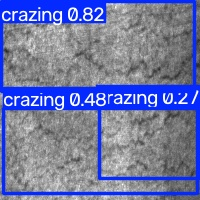

,class_id,class_name,confidence,xyxy
0,0,crazing,0.823869,"[1.735497, 1.287994, 194.886353, 91.946655]"
1,0,crazing,0.479332,"[3.330975, 108.873787, 197.41394, 193.944855]"
2,0,crazing,0.267803,"[99.395203, 106.820374, 199.897476, 178.737015]"


Saved: ./demo/predictions/crazing_100_075ab49c_predictions.jpg ./demo/predictions/crazing_100_075ab49c_predictions.json


In [2]:
if RUN_INFERENCE:
    if not CHECKPOINT.is_file():
        raise FileNotFoundError("Train a model in Phase 3 or Phase 5 before inference.")
    if IMAGE_TO_PREDICT is None or not Path(IMAGE_TO_PREDICT).is_file():
        raise FileNotFoundError("Set IMAGE_TO_PREDICT to an existing image.")
    try:
        import torch
        from ultralytics import YOLO
    except ImportError as exc:
        raise RuntimeError("Install compatible PyTorch and Ultralytics in the project .venv first.") from exc

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    model = YOLO(str(CHECKPOINT))
    predictions = model.predict(
        source=str(IMAGE_TO_PREDICT), imgsz=IMAGE_SIZE, conf=CONFIDENCE,
        device=0 if torch.cuda.is_available() else "cpu", save=False, verbose=False,
    )
    result = predictions[0]
    rendered = result.plot()
    output_image = OUTPUT_DIR / f"{Path(IMAGE_TO_PREDICT).stem}_predictions.jpg"
    Image.fromarray(rendered[..., ::-1]).save(output_image, quality=95)

    detections = []
    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            detections.append({
                "class_id": class_id,
                "class_name": result.names[class_id],
                "confidence": float(box.conf.item()),
                "xyxy": [float(v) for v in box.xyxy[0].tolist()],
            })
    record = {
        "checkpoint": str(CHECKPOINT), "input_image": str(IMAGE_TO_PREDICT),
        "confidence_threshold": CONFIDENCE, "detections": detections,
        "rendered_output": str(output_image),
    }
    output_json = OUTPUT_DIR / f"{Path(IMAGE_TO_PREDICT).stem}_predictions.json"
    output_json.write_text(json.dumps(record, indent=2) + "\n", encoding="utf-8")
    display(Image.open(output_image))
    display(pd.DataFrame(detections))
    print("Saved:", output_image, output_json)
else:
    if CHECKPOINT.is_file() and IMAGE_TO_PREDICT:
        print("Ready. Set RUN_INFERENCE=True to run this prediction.")
    else:
        print("No trained checkpoint is available yet; complete Phase 3 or Phase 5 training first.")


## Demo notes

Predictions are saved under demo/predictions. The original model checkpoint and input image are not modified.